# 01 · Modelo 1 — Autenticador de relatos (classificação de imagens)

**Projeto:** Waze da Acessibilidade · Global Solution 2026/2 · CitizenTech
**Disciplina:** Artificial Intelligence & Chatbot

## 1. Entendimento do problema

Nosso app ajuda **idosos, pessoas com mobilidade reduzida, cadeirantes e pais com carrinho de bebê** a encontrar rotas a pé com menos obstáculos.
As rotas dependem de uma lista de obstáculos que é alimentada pelos próprios cidadãos: qualquer pessoa pode **enviar a foto de um obstáculo** com a localização.

**O problema:** se qualquer foto for aceita, a lista fica cheia de lixo (selfies, fotos aleatórias, brincadeiras), e as rotas passam a desviar de obstáculos que não existem.

**O que o Modelo 1 faz:** recebe a foto e decide:

| Resultado | Ação no app |
|---|---|
| A foto mostra um obstáculo, com confiança **acima do limiar** | ✅ Relato autenticado: o tipo do obstáculo é registrado na lista |
| A foto não mostra obstáculo, ou o modelo está **inseguro** | ❌ Relato recusado: o app pede uma nova foto |

**Tipo de problema:** classificação **multiclasse** com 5 classes:

| Classe | Significado |
|---|---|
| `buraco` | buraco no piso da calçada ou da travessia |
| `calcada_irregular` | piso rachado, quebrado ou desnivelado |
| `escada_sem_rampa` | degraus/escadas sem rampa ao lado |
| `obstrucao_calcada` | calçada ocupada por objetos, veículos, comércio etc. |
| `nao_obstaculo` | qualquer foto que **não** é um obstáculo (selfie, objeto, paisagem, piso livre) |

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from PIL import Image

SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)

PASTA_DADOS = "../dados"
PASTA_MODELOS = "../modelos"

# cores fixas por classe (mesma cor em todos os gráficos)
CLASSES = ["buraco", "calcada_irregular", "escada_sem_rampa", "obstrucao_calcada", "nao_obstaculo"]
CORES = dict(zip(CLASSES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
sns.set_theme(style="whitegrid")

## 2. Análise exploratória

### 2.1 Os dados
As imagens estão em `dados/imagens/<classe>/` e o arquivo **`dados/labels.csv`** diz, para cada imagem, a classe e a **origem** (de qual base pública ela veio).

In [2]:
labels = pd.read_csv(os.path.join(PASTA_DADOS, "labels.csv"))
print("Total de imagens:", len(labels))
labels.head()

Total de imagens: 744


,arquivo,classe,origem
0,imagens/buraco/bur_0000_test_20250601_105348.jpg,buraco,CWB-Pothole-dataset (GitHub pieromorais) - Cur...
1,imagens/buraco/bur_0001_test_20250601_1053540.jpg,buraco,CWB-Pothole-dataset (GitHub pieromorais) - Cur...
2,imagens/buraco/bur_0002_test_20250601_105354.jpg,buraco,CWB-Pothole-dataset (GitHub pieromorais) - Cur...
3,imagens/buraco/bur_0003_test_20250601_105408.jpg,buraco,CWB-Pothole-dataset (GitHub pieromorais) - Cur...
4,imagens/buraco/bur_0004_test_20250601_105409.jpg,buraco,CWB-Pothole-dataset (GitHub pieromorais) - Cur...


In [3]:
# de onde vieram as imagens de cada classe
labels.groupby(["classe", "origem"]).size().rename("imagens").reset_index()

,classe,origem,imagens
0,buraco,CWB-Pothole-dataset (GitHub pieromorais) - Cur...,144
1,calcada_irregular,CrackForest-dataset (GitHub cuilimeng),150
2,escada_sem_rampa,stairs_dataset (GitHub anu71195),150
3,nao_obstaculo,Google Cloud Samples - flowers (automl),36
4,nao_obstaculo,Google Cloud Samples - generative-ai/vision,54
5,nao_obstaculo,stairs_dataset/no_stairs (GitHub anu71195),60
6,obstrucao_calcada,Sidewalk-Obstacle-Dataset (GitHub T3qu1laSuns3...,150


In [4]:
# conferindo se todos os arquivos do labels.csv existem e não há duplicados
existe = labels["arquivo"].apply(lambda a: os.path.exists(os.path.join(PASTA_DADOS, a)))
print("Arquivos encontrados:", existe.sum(), "de", len(labels))
print("Nomes duplicados:", labels["arquivo"].duplicated().sum())
print("Valores vazios:", labels.isna().sum().sum())

Arquivos encontrados: 744 de 744
Nomes duplicados: 0
Valores vazios: 0


### 2.2 Quantidade de imagens por classe

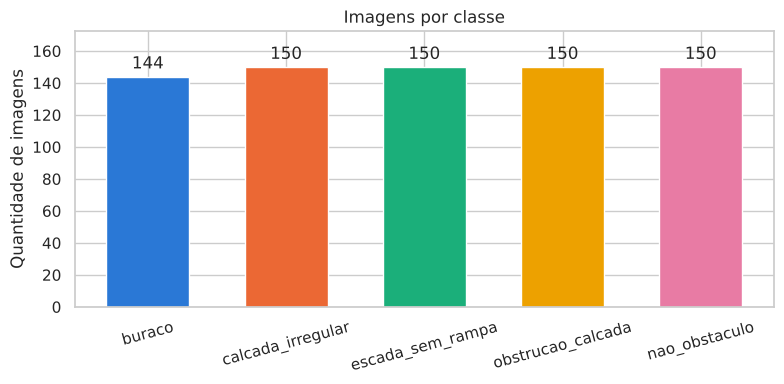

Proporção da maior para a menor classe: 1.04


In [5]:
contagem = labels["classe"].value_counts().reindex(CLASSES)

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(contagem.index, contagem.values, color=[CORES[c] for c in contagem.index], width=0.6)
ax.bar_label(barras, padding=3)
ax.set_title("Imagens por classe")
ax.set_ylabel("Quantidade de imagens")
ax.set_ylim(0, contagem.max() * 1.15)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("Proporção da maior para a menor classe:", round(contagem.max() / contagem.min(), 2))

**Insight:** as classes estão **equilibradas** (144 a 150 imagens cada; a maior tem só 4% a mais que a menor).
Fizemos isso de propósito: baixamos **150 imagens por classe**. Na classe `buraco` ficaram 144 porque só essas fotos da base original tinham a marcação do buraco.
Com classes equilibradas, a **acurácia** já é uma métrica confiável, e o modelo não fica "viciado" em uma classe só.

### 2.3 Tamanho das imagens
Antes de entrar no projeto, todas as imagens foram reduzidas para **no máximo 512 pixels** no lado maior (para o `.zip` não ficar pesado).
Mesmo assim, as proporções variam (fotos em pé, deitadas e quadradas).

In [6]:
larguras, alturas = [], []
for arquivo in labels["arquivo"]:
    with Image.open(os.path.join(PASTA_DADOS, arquivo)) as img:
        larguras.append(img.width)
        alturas.append(img.height)
labels["largura"] = larguras
labels["altura"] = alturas
labels["proporcao"] = (labels["largura"] / labels["altura"]).round(2)

labels.groupby("classe")[["largura", "altura", "proporcao"]].agg(["min", "mean", "max"]).round(0)

largura             altura             proporcao          
                      min   mean  max    min   mean  max       min mean  max
classe                                                                      
buraco                512  512.0  512    384  384.0  385       1.0  1.0  1.0
calcada_irregular     320  478.0  480    320  322.0  480       1.0  1.0  2.0
escada_sem_rampa      256  323.0  512    256  498.0  512       0.0  1.0  2.0
nao_obstaculo         159  387.0  512    213  422.0  512       0.0  1.0  2.0
obstrucao_calcada     512  512.0  512    277  286.0  299       2.0  2.0  2.0

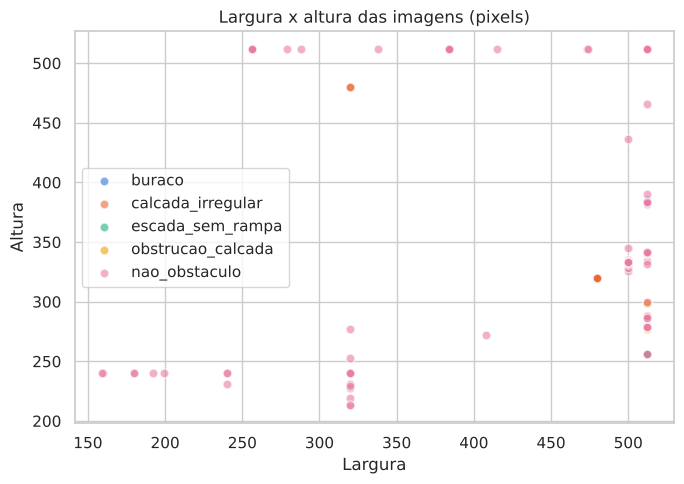

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
for classe in CLASSES:
    parte = labels[labels["classe"] == classe]
    ax.scatter(parte["largura"], parte["altura"], s=40, alpha=0.6, color=CORES[classe],
               label=classe, edgecolor="white", linewidth=1)
ax.set_title("Largura x altura das imagens (pixels)")
ax.set_xlabel("Largura")
ax.set_ylabel("Altura")
ax.legend()
plt.tight_layout()
plt.show()

**Insight:** os tamanhos variam bastante. As fotos de escadas estão quase todas em pé (altura > largura), e as de buracos são recortes deitados.
Isso **não é problema** para o nosso modelo, porque na preparação **todas as imagens são redimensionadas para 224 × 224 pixels**, o tamanho que o modelo pré-treinado espera.
Mas é um alerta: o formato da foto pode virar uma "dica" para o modelo. Por isso analisamos os erros no final.

### 2.4 Exemplos de cada classe

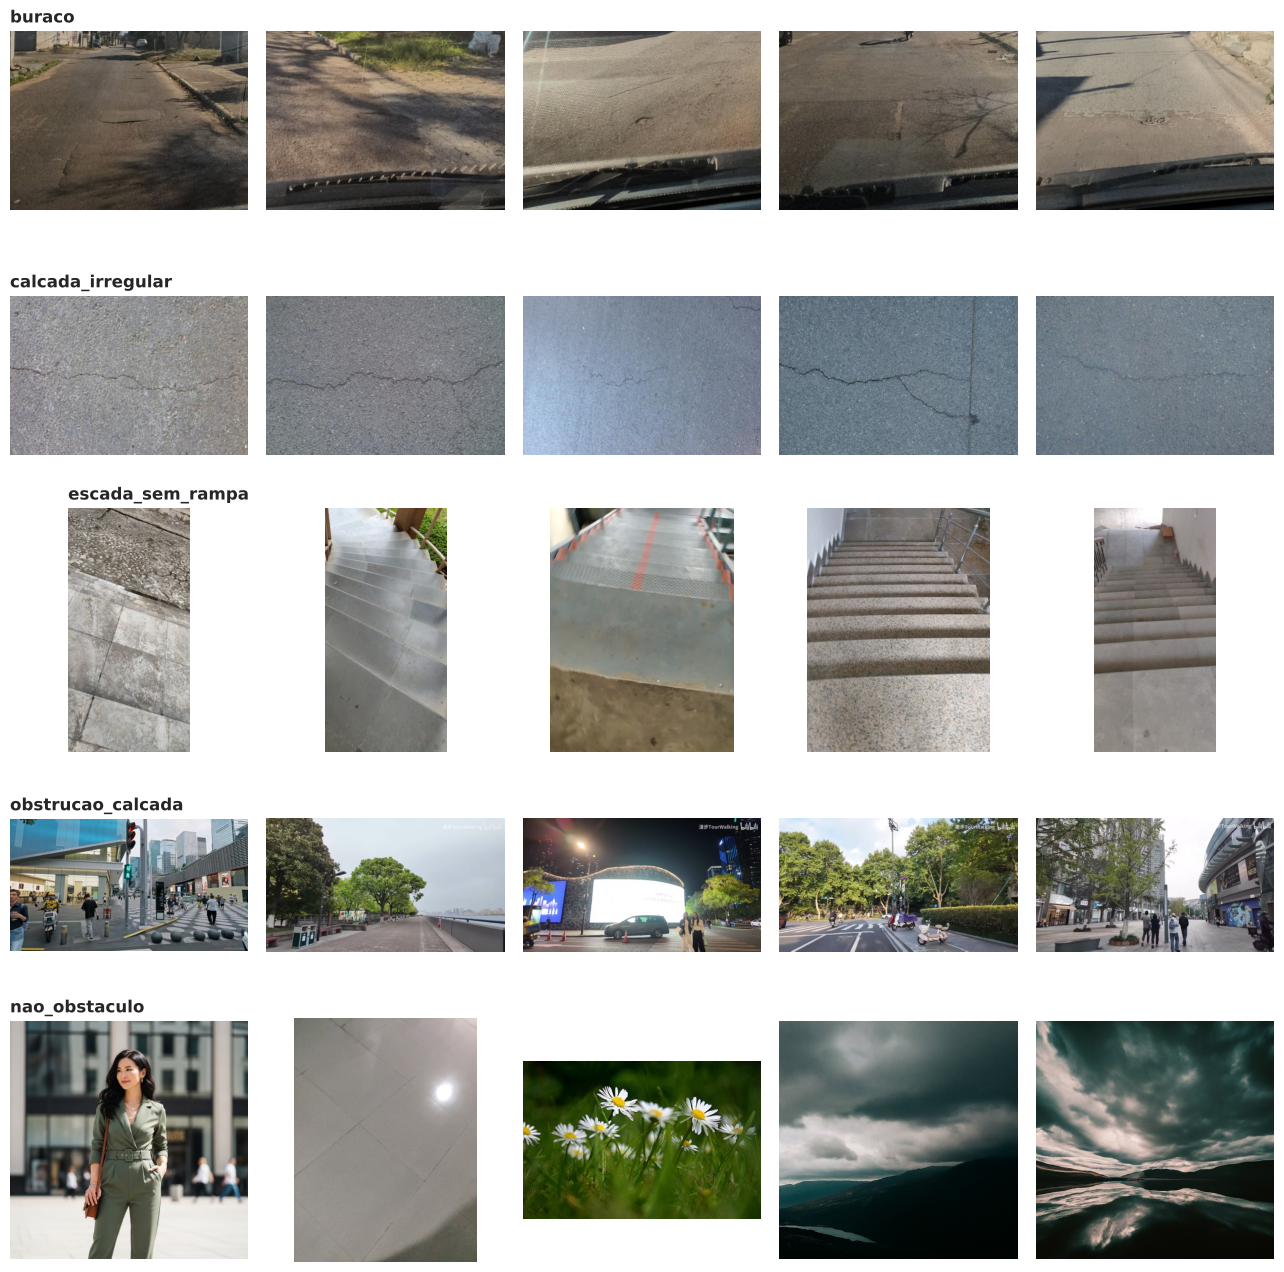

In [8]:
fig, eixos = plt.subplots(len(CLASSES), 5, figsize=(13, 13))
for i, classe in enumerate(CLASSES):
    amostra = labels[labels["classe"] == classe].sample(5, random_state=SEMENTE)
    for j, arquivo in enumerate(amostra["arquivo"]):
        eixo = eixos[i, j]
        eixo.imshow(Image.open(os.path.join(PASTA_DADOS, arquivo)))
        eixo.axis("off")
        if j == 0:
            eixo.set_title(classe, loc="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

**Insights da grade de exemplos:**
- `buraco`: recortes de ruas de **Curitiba/PR** (fotos tiradas de dentro de um carro). Em algumas aparece um pedaço do painel do carro: é uma **limitação** da base.
- `calcada_irregular`: fotos de perto de pisos **rachados** (base CrackForest).
- `escada_sem_rampa`: escadas internas e externas, sem rampa.
- `obstrucao_calcada`: cenas de calçadas **ocupadas** (pessoas, bicicletas, motos, carros, comércio). É a classe mais "genérica": o obstáculo nem sempre está no centro da foto.
- `nao_obstaculo`: mistura de pessoas, objetos, comida, flores, paisagens e **pisos livres**. Os pisos livres são importantes: sem eles, o modelo poderia aprender que "toda foto de chão é obstáculo".

## 3. Preparação dos dados

### 3.1 O que é um *embedding*?
Uma foto, para o computador, é uma grade de milhares de números (pixels). Comparar pixels diretamente não funciona: a mesma escada fotografada com luz diferente teria pixels totalmente diferentes.

Um **embedding** é um **resumo numérico da imagem**: uma lista de **1280 números** que descreve *o que aparece na foto* (bordas, texturas, formas, objetos), e não a cor exata de cada pixel.
Fotos parecidas (duas escadas) geram embeddings parecidos; fotos diferentes (uma escada e uma selfie) geram embeddings diferentes.

### 3.2 Por que usar um modelo pré-treinado (*transfer learning*)?
Usamos a rede **MobileNetV2**, que o Google já treinou com **mais de 1 milhão de imagens** (base ImageNet). Ela já "sabe enxergar" bordas, texturas e objetos.

- **Nós não treinamos a MobileNetV2 de novo.** Só usamos ela para transformar cada foto em um embedding.
- Depois treinamos um **classificador simples do scikit-learn** em cima desses embeddings.

Isso é **transfer learning** (transferência de aprendizado), ideal para o nosso caso:

| Nossa situação | Por que o transfer learning ajuda |
|---|---|
| Poucas imagens (~150 por classe) | Treinar uma rede do zero precisaria de dezenas de milhares |
| Pouco tempo e sem placa de vídeo | Extrair os embeddings leva poucos minutos no processador |
| A API precisa responder rápido | A MobileNetV2 é **leve**, feita para rodar até em celular |

In [9]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # esconde mensagens técnicas do TensorFlow (precisa vir antes do import)
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

tf.random.set_seed(SEMENTE)
tf.get_logger().setLevel("ERROR")

# include_top=False -> tira a última camada (que classificaria as 1000 classes do ImageNet)
# pooling="avg"     -> resume cada imagem em um vetor de 1280 números (o embedding)
extrator = MobileNetV2(weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
extrator.trainable = False  # congelado: não vamos treinar a rede
print("Tamanho do embedding:", extrator.output_shape[1])

I0000 00:00:1794442238.227644    2109 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794442239.253035    2109 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Tamanho do embedding: 1280


In [10]:
TAMANHO = (224, 224)

def carregar_imagem(caminho):
    # abre a foto, garante 3 canais (RGB) e redimensiona para 224x224
    img = Image.open(caminho).convert("RGB").resize(TAMANHO)
    return np.array(img, dtype="float32")

def gerar_embeddings(lista_de_caminhos, tamanho_lote=32):
    embeddings = []
    for inicio in range(0, len(lista_de_caminhos), tamanho_lote):
        lote = [carregar_imagem(c) for c in lista_de_caminhos[inicio:inicio + tamanho_lote]]
        lote = preprocess_input(np.stack(lote))  # ajusta os pixels para a escala que a MobileNetV2 espera
        embeddings.append(extrator.predict(lote, verbose=0))
    return np.vstack(embeddings)

caminhos = [os.path.join(PASTA_DADOS, a) for a in labels["arquivo"]]
X = gerar_embeddings(caminhos)
y = labels["classe"].values
print("Formato de X:", X.shape, "-> (imagens, números do embedding)")

Formato de X: (744, 1280) -> (imagens, números do embedding)


In [11]:
# salvando os embeddings em .csv (dados tabulares prontos para o scikit-learn)
colunas = [f"e{i}" for i in range(X.shape[1])]
tabela_emb = pd.DataFrame(X.round(5), columns=colunas)
tabela_emb.insert(0, "classe", y)
tabela_emb.insert(0, "arquivo", labels["arquivo"])
tabela_emb.to_csv(os.path.join(PASTA_DADOS, "embeddings.csv"), index=False)
tabela_emb.iloc[:5, :8]

,arquivo,classe,e0,e1,e2,e3,e4,e5
0,imagens/buraco/bur_0000_test_20250601_105348.jpg,buraco,2.67152,0.02932,0.00000,0.72967,0.09264,0.02312
1,imagens/buraco/bur_0001_test_20250601_1053540.jpg,buraco,0.41750,1.11966,0.68783,1.03264,0.42581,0.10582
2,imagens/buraco/bur_0002_test_20250601_105354.jpg,buraco,2.24990,0.67598,0.88754,0.36794,0.38286,0.80134
3,imagens/buraco/bur_0003_test_20250601_105408.jpg,buraco,1.06175,0.08643,0.39882,0.03196,0.01890,0.00000
4,imagens/buraco/bur_0004_test_20250601_105409.jpg,buraco,1.24738,0.91765,0.94117,0.12541,0.79380,0.02055


### 3.3 Os embeddings separam as classes?
Para "enxergar" 1280 números em um gráfico, usamos o **PCA**, que comprime os embeddings em **2 números** mantendo o máximo de informação possível.
É só uma visualização: o classificador vai usar os 1280 números.

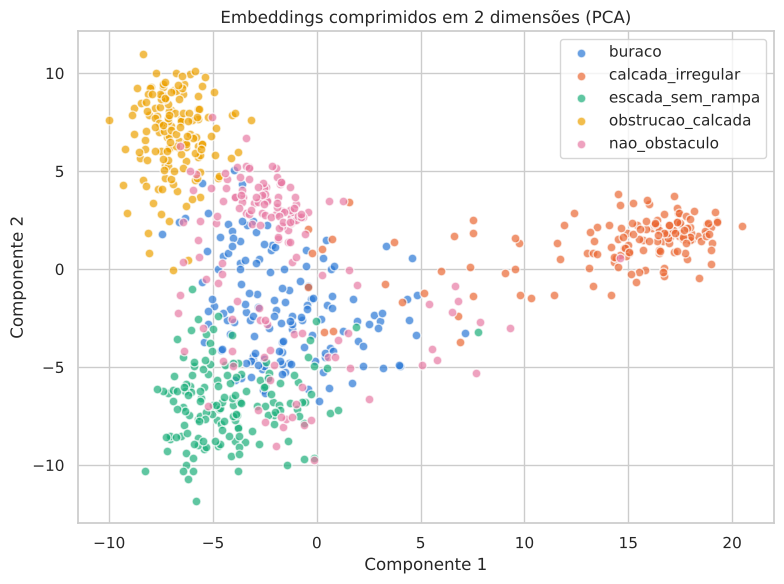

Informação mantida pelos 2 componentes: 23%


In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEMENTE)
X_2d = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
for classe in CLASSES:
    m = y == classe
    ax.scatter(X_2d[m, 0], X_2d[m, 1], s=40, alpha=0.7, color=CORES[classe], label=classe,
               edgecolor="white", linewidth=1)
ax.set_title("Embeddings comprimidos em 2 dimensões (PCA)")
ax.set_xlabel("Componente 1")
ax.set_ylabel("Componente 2")
ax.legend()
plt.tight_layout()
plt.show()
print("Informação mantida pelos 2 componentes:", f"{pca.explained_variance_ratio_.sum():.0%}")

**Insights:** os 2 componentes guardam só cerca de 1/4 da informação, mas já aparecem **grupos por classe**:
- `calcada_irregular` (rachaduras de perto) forma um grupo **bem isolado** à direita;
- `obstrucao_calcada` fica em cima à esquerda e `escada_sem_rampa` embaixo à esquerda;
- `buraco` e `nao_obstaculo` ficam no meio e se misturam um pouco com os vizinhos. É ali que esperamos os erros.

Isso mostra que a MobileNetV2 **já captura o que diferencia** as classes, então um classificador simples deve funcionar bem.

⚠️ **Cuidado:** um grupo muito separado pode significar que a classe é fácil **ou** que todas as suas fotos vêm da mesma base, com o mesmo "estilo" (câmera, formato, iluminação). Todas as fotos de `obstrucao_calcada`, por exemplo, são cenas de rua no formato 16:9 da mesma base. Voltamos a isso na avaliação.

### 3.4 Divisão em treino e teste
- **80% treino** (o modelo aprende) e **20% teste** (o modelo nunca viu: simula fotos novas de usuários).
- A divisão é **estratificada**: cada classe mantém a mesma proporção nos dois grupos.

In [13]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(y))
X_treino, X_teste, y_treino, y_teste, idx_treino, idx_teste = train_test_split(
    X, y, indices, test_size=0.2, stratify=y, random_state=SEMENTE)

print("Treino:", X_treino.shape[0], "imagens | Teste:", X_teste.shape[0], "imagens")
pd.DataFrame({"treino": pd.Series(y_treino).value_counts(), "teste": pd.Series(y_teste).value_counts()}).reindex(CLASSES)

Treino: 595 imagens | Teste: 149 imagens


,treino,teste
buraco,115,29
calcada_irregular,120,30
escada_sem_rampa,120,30
obstrucao_calcada,120,30
nao_obstaculo,120,30


## 4. Treinamento

Comparamos **3 classificadores** do scikit-learn sobre os embeddings:

| Modelo | Ideia em uma frase |
|---|---|
| **Regressão Logística** | encontra "linhas de separação" entre as classes e devolve uma probabilidade para cada uma |
| **SVM** (máquina de vetores de suporte) | encontra a separação com a **maior margem** possível entre as classes |
| **Random Forest** | vota entre centenas de árvores de decisão |

Regressão Logística e SVM usam um `StandardScaler` antes (deixa todos os 1280 números na mesma escala). Juntamos os dois passos em um **Pipeline**.

Para comparar de forma justa, usamos **validação cruzada com 5 dobras** só nos dados de treino: o treino é dividido em 5 partes, o modelo treina em 4 e é testado na 5ª, cinco vezes.
A métrica é o **F1-score macro** (média do F1 de cada classe; trata todas as classes com o mesmo peso).

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

modelos = {
    "Regressão Logística": Pipeline([
        ("escala", StandardScaler()),
        ("modelo", LogisticRegression(C=0.1, max_iter=2000, random_state=SEMENTE))]),
    "SVM": Pipeline([
        ("escala", StandardScaler()),
        # o SVM sozinho não devolve probabilidade; o CalibratedClassifierCV converte as "notas" do SVM em probabilidades
        ("modelo", CalibratedClassifierCV(SVC(kernel="rbf", C=10, random_state=SEMENTE), ensemble=False))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEMENTE, n_jobs=-1),
}

dobras = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
resultados = []
for nome, modelo in modelos.items():
    notas = cross_val_score(modelo, X_treino, y_treino, cv=dobras, scoring="f1_macro")
    resultados.append({"modelo": nome, "f1_macro_medio": notas.mean(), "desvio": notas.std()})
    print(f"{nome:20s} F1 macro = {notas.mean():.3f} (± {notas.std():.3f})")

resultados = pd.DataFrame(resultados).sort_values("f1_macro_medio", ascending=False)

Regressão Logística  F1 macro = 0.956 (± 0.012)


SVM                  F1 macro = 0.948 (± 0.015)


Random Forest        F1 macro = 0.939 (± 0.017)


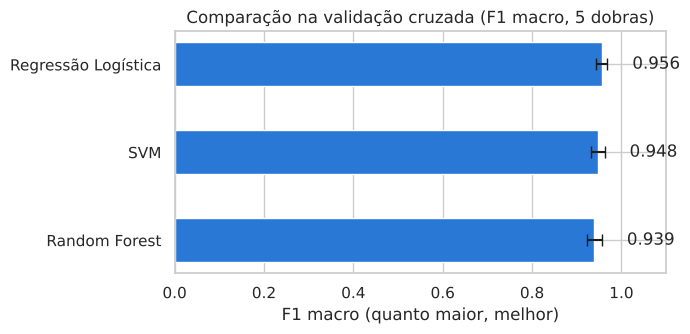

Melhor modelo: Regressão Logística


In [15]:
fig, ax = plt.subplots(figsize=(7, 3.5))
barras = ax.barh(resultados["modelo"], resultados["f1_macro_medio"], xerr=resultados["desvio"],
                 color="#2a78d6", height=0.5, capsize=4)
ax.bar_label(barras, labels=[f"{v:.3f}" for v in resultados["f1_macro_medio"]], padding=18)
ax.set_xlim(0, 1.1)
ax.invert_yaxis()
ax.set_title("Comparação na validação cruzada (F1 macro, 5 dobras)")
ax.set_xlabel("F1 macro (quanto maior, melhor)")
plt.tight_layout()
plt.show()

melhor_nome = resultados.iloc[0]["modelo"]
print("Melhor modelo:", melhor_nome)

**Insight:** Regressão Logística e SVM ficam praticamente empatadas e as duas superam o Random Forest. Isso é esperado: com **1280 números por imagem e poucas centenas de exemplos**, modelos que traçam fronteiras (lineares ou com margem) costumam funcionar melhor que árvores, que dividem um número por vez.
Escolhemos o modelo com **maior F1 macro** na validação cruzada (impresso acima) e treinamos com todo o conjunto de treino.

In [16]:
melhor_modelo = modelos[melhor_nome]
melhor_modelo.fit(X_treino, y_treino)
print("Classes que o modelo conhece:", list(melhor_modelo.classes_))

Classes que o modelo conhece: ['buraco', 'calcada_irregular', 'escada_sem_rampa', 'nao_obstaculo', 'obstrucao_calcada']


## 5. Avaliação de desempenho (conjunto de teste)

Métricas usadas:
- **Acurácia:** % de fotos com a classe correta.
- **Precisão** (por classe): das fotos que o modelo chamou de "escada", quantas eram escada mesmo?
- **Recall** (por classe): de todas as escadas reais, quantas o modelo encontrou?
- **F1-score:** equilíbrio entre precisão e recall.
- **Matriz de confusão:** mostra *quais classes* o modelo confunde.

In [17]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

y_previsto = melhor_modelo.predict(X_teste)
print(f"Acurácia no teste: {accuracy_score(y_teste, y_previsto):.3f}\n")
print(classification_report(y_teste, y_previsto, labels=CLASSES, digits=3))

Acurácia no teste: 0.953

                   precision    recall  f1-score   support

           buraco      0.935     1.000     0.967        29
calcada_irregular      0.935     0.967     0.951        30
 escada_sem_rampa      1.000     0.900     0.947        30
obstrucao_calcada      1.000     1.000     1.000        30
    nao_obstaculo      0.900     0.900     0.900        30

         accuracy                          0.953       149
        macro avg      0.954     0.953     0.953       149
     weighted avg      0.954     0.953     0.953       149



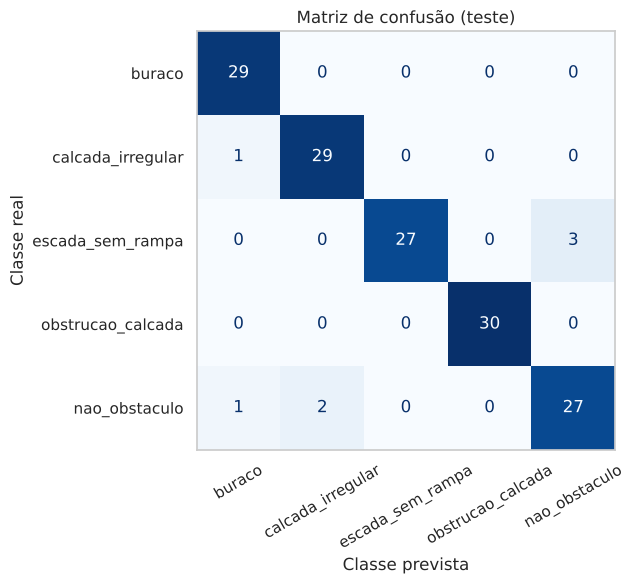

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_teste, y_previsto, labels=CLASSES),
                       display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30)
ax.set_title("Matriz de confusão (teste)")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.grid(False)
plt.tight_layout()
plt.show()

**Como ler a matriz:** a diagonal são os acertos. Fora da diagonal, cada número é um erro: a linha diz a classe real e a coluna diz o que o modelo previu.
O erro **mais grave** para o app é uma foto da linha `nao_obstaculo` cair em uma coluna de obstáculo: seria um relato falso aceito.

### 5.1 Exemplos de imagens classificadas errado

Quantidade de erros no teste: 7 de 149


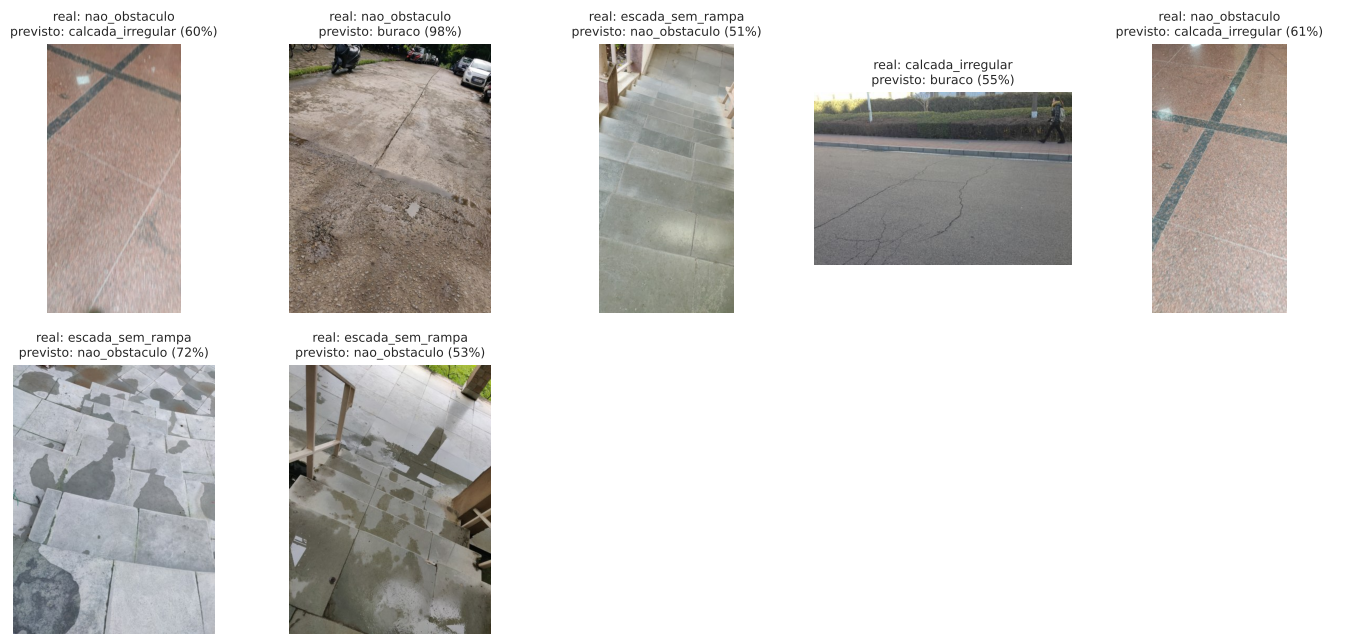

In [19]:
probas_teste = melhor_modelo.predict_proba(X_teste)
classes_modelo = list(melhor_modelo.classes_)
erros = np.where(y_previsto != y_teste)[0]
print("Quantidade de erros no teste:", len(erros), "de", len(y_teste))

if len(erros) > 0:
    n = min(len(erros), 10)
    colunas_grade = 5
    linhas_grade = int(np.ceil(n / colunas_grade))
    fig, eixos = plt.subplots(linhas_grade, colunas_grade, figsize=(14, 3.3 * linhas_grade), squeeze=False)
    for k, eixo in enumerate(eixos.flat):
        eixo.axis("off")
        if k >= n:
            continue
        i = erros[k]
        arquivo = labels["arquivo"].iloc[idx_teste[i]]
        conf = probas_teste[i].max()
        eixo.imshow(Image.open(os.path.join(PASTA_DADOS, arquivo)))
        eixo.set_title(f"real: {y_teste[i]}\nprevisto: {y_previsto[i]} ({conf:.0%})", fontsize=9)
    plt.tight_layout()
    plt.show()

**Interpretação dos erros** (veja a matriz e as imagens acima):
1. **Escada fotografada de cima → `nao_obstaculo`.** Vista de cima, a escada vira uma sequência de faixas no chão, parecida com um piso liso. É o erro mais frequente, e acontece com **confiança baixa** (50% a 75%).
2. **Piso liso com juntas/reflexo (`nao_obstaculo`) → `calcada_irregular`.** As linhas entre as placas do piso lembram rachaduras. Também acontece com confiança baixa (~60%).
3. **`calcada_irregular` → `buraco`:** uma rachadura larga parece um buraco raso. Para o usuário, esse erro é **leve**: nos dois casos o trecho deve ser evitado.
4. **Um "erro" que na verdade é acerto:** uma foto rotulada como `nao_obstaculo` foi classificada como `buraco` com ~98% de confiança. Olhando a imagem, ela mostra **um piso quebrado e com poças**. Ela veio da pasta "sem escadas" da base original, e o rótulo que herdamos não serve para o nosso problema. Isso é **ruído de rotulagem**: nem todo rótulo de base pública está certo para o nosso uso.
5. **`obstrucao_calcada` acertou 100%,** mas isso deve ser visto com cautela: todas as fotos dessa classe vêm de uma única base (mesmo formato e estilo). O modelo pode estar reconhecendo o "estilo da base", e com fotos reais de São Paulo o desempenho dessa classe tende a cair.

**Conclusão:** quase todos os erros de verdade acontecem com **confiança baixa**. É isso que o **limiar de confiança** (próxima seção) aproveita: na dúvida, o app recusa e pede outra foto.

### 5.2 Definindo o limiar de confiança para autenticar um relato

A regra do app é:

> **Autenticar** se a classe prevista for um obstáculo **e** a confiança (maior probabilidade) for **≥ limiar**. Caso contrário, **recusar** e pedir uma nova foto.

Existem dois tipos de erro, com custos diferentes:

| Erro | Consequência | Gravidade |
|---|---|---|
| **Aceitar uma foto falsa** (não é obstáculo) | Obstáculo inexistente entra na lista e as rotas desviam à toa; o sistema perde credibilidade | **Alta** |
| **Recusar uma foto verdadeira** | O usuário tira outra foto | Baixa |

Por isso, o limiar deve ser **alto o bastante para quase nunca aceitar foto falsa**, mesmo que algumas fotos boas sejam recusadas.

**Como escolhemos sem "espiar" o teste:** calculamos as probabilidades do conjunto de **treino** usando validação cruzada (`cross_val_predict`): cada foto recebe a previsão de um modelo que não a viu. Assim temos **600 fotos** para escolher o limiar, e o teste fica guardado para a conferência final.

In [20]:
from sklearn.model_selection import cross_val_predict

probas_cv = cross_val_predict(melhor_modelo, X_treino, y_treino, cv=dobras, method="predict_proba")

def avaliar_limiar(probas, y_real, limiar):
    classe_prev = np.array(classes_modelo)[probas.argmax(axis=1)]
    confianca = probas.max(axis=1)
    autenticado = (classe_prev != "nao_obstaculo") & (confianca >= limiar)
    eh_obstaculo = y_real != "nao_obstaculo"
    return {
        "limiar": limiar,
        # das fotos SEM obstáculo, quantas foram aceitas (queremos ~0)
        "falsos_aceitos": autenticado[~eh_obstaculo].mean(),
        # das fotos COM obstáculo, quantas foram recusadas (custo: usuário tira outra foto)
        "verdadeiros_recusados": (~autenticado[eh_obstaculo]).mean(),
        # dos relatos aceitos, quantos estão com o TIPO certo
        "tipo_correto_nos_aceitos": (classe_prev[autenticado] == y_real[autenticado]).mean(),
    }

limiares = np.round(np.arange(0.30, 0.96, 0.05), 2)
tabela_limiar = pd.DataFrame([avaliar_limiar(probas_cv, y_treino, l) for l in limiares])
tabela_limiar.style.format("{:.1%}", subset=["falsos_aceitos", "verdadeiros_recusados", "tipo_correto_nos_aceitos"])

,limiar,falsos_aceitos,verdadeiros_recusados,tipo_correto_nos_aceitos
0,0.300000,10.8%,1.9%,96.5%
1,0.350000,10.8%,1.9%,96.5%
2,0.400000,10.8%,1.9%,96.5%
3,0.450000,10.0%,1.9%,96.7%
4,0.500000,9.2%,2.5%,97.0%
5,0.550000,7.5%,2.9%,97.7%
6,0.600000,6.7%,3.2%,98.1%
7,0.650000,5.8%,3.8%,98.3%
8,0.700000,5.0%,4.6%,98.5%
9,0.750000,2.5%,4.8%,99.1%


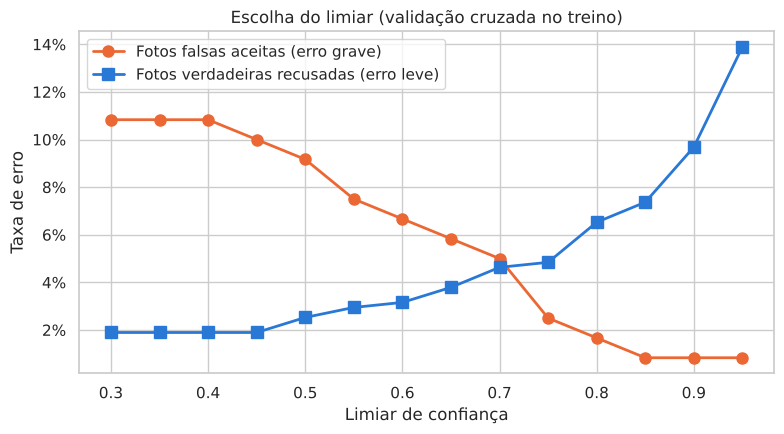

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tabela_limiar["limiar"], tabela_limiar["falsos_aceitos"], color="#eb6834", linewidth=2,
        marker="o", markersize=8, label="Fotos falsas aceitas (erro grave)")
ax.plot(tabela_limiar["limiar"], tabela_limiar["verdadeiros_recusados"], color="#2a78d6", linewidth=2,
        marker="s", markersize=8, label="Fotos verdadeiras recusadas (erro leve)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Limiar de confiança")
ax.set_ylabel("Taxa de erro")
ax.set_title("Escolha do limiar (validação cruzada no treino)")
ax.legend()
plt.tight_layout()
plt.show()

In [22]:
# REGRA DE ESCOLHA: o menor limiar em que no máximo 1% das fotos falsas é aceita,
# e nunca abaixo de 0.60 (abaixo disso o modelo estaria "chutando" entre duas classes)
LIMITE_FALSOS = 0.01
candidatos = tabela_limiar[(tabela_limiar["falsos_aceitos"] <= LIMITE_FALSOS) & (tabela_limiar["limiar"] >= 0.60)]
LIMIAR = float(candidatos["limiar"].min()) if len(candidatos) > 0 else 0.90
print("Limiar escolhido:", LIMIAR)
tabela_limiar[tabela_limiar["limiar"] == LIMIAR]

Limiar escolhido: 0.85


,limiar,falsos_aceitos,verdadeiros_recusados,tipo_correto_nos_aceitos
11,0.85,0.008333,0.073684,0.997732


**Justificativa do limiar:** escolhemos o **menor limiar que mantém as fotos falsas aceitas em no máximo 1%**, com piso de 0,60.
Assim priorizamos a **confiabilidade da lista de obstáculos** (o erro grave), e o custo é recusar uma parte das fotos verdadeiras: o usuário só precisa tirar outra foto, mais de perto.
Também não usamos um limiar mais alto que o necessário, porque recusar fotos demais desanimaria os cidadãos de colaborar.

### 5.3 Conferência final no teste (com o limiar)

In [23]:
final = avaliar_limiar(probas_teste, y_teste, LIMIAR)
eh_obstaculo = y_teste != "nao_obstaculo"
print(f"Limiar: {LIMIAR}")
print(f"Fotos sem obstáculo no teste: {(~eh_obstaculo).sum()} | aceitas por engano: {final['falsos_aceitos']:.1%}")
print(f"Fotos com obstáculo no teste: {eh_obstaculo.sum()} | recusadas (pedir nova foto): {final['verdadeiros_recusados']:.1%}")
print(f"Relatos aceitos com o tipo certo: {final['tipo_correto_nos_aceitos']:.1%}")

Limiar: 0.85
Fotos sem obstáculo no teste: 30 | aceitas por engano: 3.3%
Fotos com obstáculo no teste: 119 | recusadas (pedir nova foto): 12.6%
Relatos aceitos com o tipo certo: 99.0%


**Interpretação:**
- O teste tem só **30 fotos sem obstáculo**, então **cada foto vale 3,3 pontos percentuais**. Uma taxa de 3,3% de falsos aceitos significa **1 foto**.
- Essa foto é justamente a do **piso quebrado com poças** vista na seção 5.1: um rótulo errado da base, em que o modelo na verdade acertou. Desconsiderando esse caso, nenhuma foto realmente sem obstáculo foi aceita.
- Cerca de **1 em cada 8 fotos verdadeiras é recusada**. É o preço da segurança: o usuário recebe a mensagem "tire outra foto mais de perto".
- Dos relatos aceitos, praticamente todos ficam com o **tipo correto**. A lista de obstáculos que alimenta as rotas fica confiável.

**Limitações e próximos passos:**
- As imagens vêm de bases públicas de outras cidades e países (Curitiba e cidades da China, entre outras). O ideal é **trocar ou complementar com fotos de São Paulo** tiradas pelo grupo e pelos primeiros usuários.
- Os rótulos de bases públicas podem ter erros (como o piso quebrado na pasta "sem escadas"). Uma **revisão manual** das imagens de `nao_obstaculo` melhoraria a base.
- A classe `obstrucao_calcada` usa cenas de rua inteiras. Fotos focadas no obstáculo (carro na calçada, entulho, lixeira) melhorariam essa classe.
- Em produção, os relatos recusados com confiança "quase no limiar" podem ir para uma **revisão humana** em vez de serem descartados.

### 5.4 Teste com fotos de fora da base
O conjunto de teste veio **das mesmas bases** do treino. Para simular melhor o mundo real, testamos **7 fotos que não vêm de nenhuma das bases usadas** (imagens de exemplo públicas do Google Cloud, pasta `api/testes/fotos_fora_da_base/`). Nenhuma delas é um obstáculo, então **todas deveriam ser recusadas**.

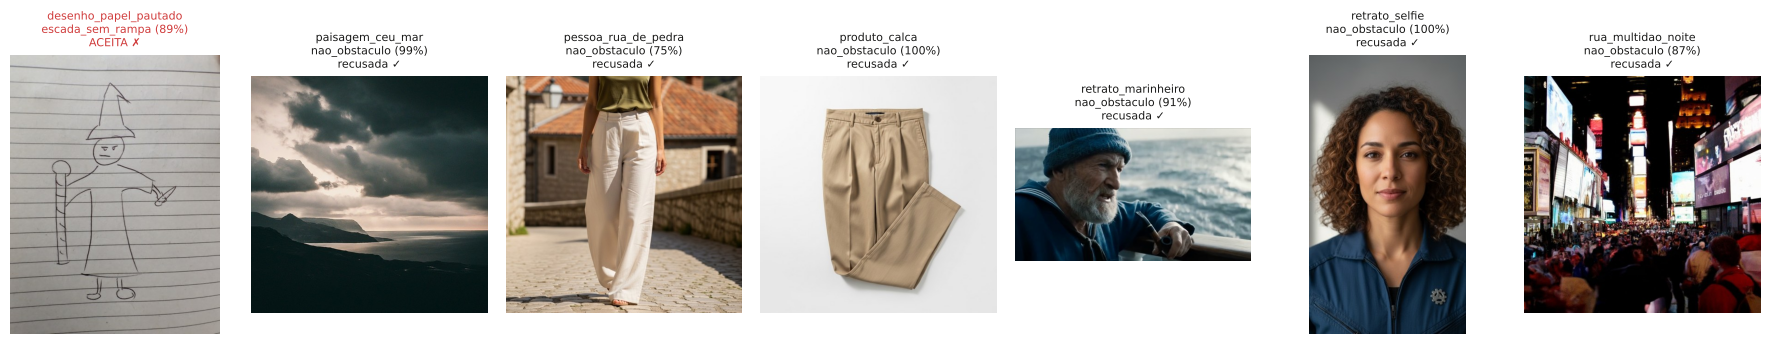

In [24]:
pasta_extra = "../api/testes/fotos_fora_da_base"
arquivos_extra = sorted(os.listdir(pasta_extra))
emb_extra = gerar_embeddings([os.path.join(pasta_extra, a) for a in arquivos_extra])
prob_extra = melhor_modelo.predict_proba(emb_extra)

fig, eixos = plt.subplots(1, len(arquivos_extra), figsize=(18, 3.6))
for eixo, arquivo, prob in zip(eixos, arquivos_extra, prob_extra):
    classe = classes_modelo[prob.argmax()]
    aceito = classe != "nao_obstaculo" and prob.max() >= LIMIAR
    eixo.imshow(Image.open(os.path.join(pasta_extra, arquivo)))
    eixo.axis("off")
    eixo.set_title(f"{arquivo.replace('.jpg', '')}\n{classe} ({prob.max():.0%})\n{'ACEITA ✗' if aceito else 'recusada ✓'}",
                   fontsize=8, color="#d03b3b" if aceito else "#1a1a19")
plt.tight_layout()
plt.show()

**Interpretação:** retratos, paisagem, rua à noite e fotos de produto são **recusados**. Mas o **desenho em papel pautado** foi aceito como `escada_sem_rampa`.

**Por quê?** As **linhas horizontais paralelas** do caderno parecem a borda dos degraus. O modelo aprendeu um atalho: "muitas listras horizontais = escada". Ele nunca viu, na classe `nao_obstaculo`, uma foto com listras que **não** fosse escada.

**O que isso ensina:**
- Métricas altas no teste **não garantem** bom comportamento com fotos de fora da base. Testar com imagens novas é obrigatório.
- **Correção:** acrescentar a `nao_obstaculo` fotos com padrões listrados (cadernos, persianas, grades, faixas de pedestre) e treinar de novo.
- **Proteção extra no app:** relatos aceitos podem exigir **confirmação de outro usuário** no mesmo local antes de mudar as rotas.

## 6. Exportação do modelo
Salvamos com o `joblib` um **dicionário** com tudo o que a API precisa:
- o classificador treinado (Pipeline);
- a lista de classes;
- o limiar de confiança;
- as informações do extrator de embeddings (a API precisa gerar o embedding **do mesmo jeito**).

Também exportamos a **MobileNetV2 em formato TensorFlow Lite** (`.tflite`), a versão "leve" do TensorFlow, feita para celulares e servidores pequenos.
**Por quê?** Só importar o TensorFlow completo ocupa mais de 500 MB de memória, mais do que o plano gratuito do Render (onde a API fica publicada) oferece.
Com o `.tflite`, a API roda com o pacote `ai-edge-litert` (runtime oficial do Google) e usa menos de 200 MB.
A rede é **a mesma**: só muda o formato do arquivo. Conferimos isso logo abaixo.

In [25]:
pacote = {
    "modelo": melhor_modelo,
    "nome_modelo": melhor_nome,
    "classes": classes_modelo,
    "classe_negativa": "nao_obstaculo",
    "limiar": LIMIAR,
    "extrator": {"rede": "MobileNetV2", "pesos": "imagenet", "tamanho": [224, 224], "pooling": "avg",
                 "arquivo_tflite": "extrator_mobilenetv2.tflite"},
    "metricas_teste": {
        "acuracia": round(float(accuracy_score(y_teste, y_previsto)), 4),
        "falsos_aceitos": round(float(final["falsos_aceitos"]), 4),
        "verdadeiros_recusados": round(float(final["verdadeiros_recusados"]), 4),
    },
}
os.makedirs(PASTA_MODELOS, exist_ok=True)
caminho_modelo = os.path.join(PASTA_MODELOS, "autenticador.joblib")
joblib.dump(pacote, caminho_modelo)
print("Modelo salvo em", caminho_modelo, f"({os.path.getsize(caminho_modelo) / 1e6:.1f} MB)")

Modelo salvo em ../modelos/autenticador.joblib (0.1 MB)


In [26]:
import contextlib
import io

# converte a MobileNetV2 (extrator) para TensorFlow Lite
conversor = tf.lite.TFLiteConverter.from_keras_model(extrator)
with contextlib.redirect_stdout(io.StringIO()):  # esconde o texto longo que a conversão imprime
    modelo_tflite = conversor.convert()

caminho_tflite = os.path.join(PASTA_MODELOS, "extrator_mobilenetv2.tflite")
with open(caminho_tflite, "wb") as f:
    f.write(modelo_tflite)
print("Extrator salvo em", caminho_tflite, f"({os.path.getsize(caminho_tflite) / 1e6:.1f} MB)")

Extrator salvo em ../modelos/extrator_mobilenetv2.tflite (8.9 MB)


In [27]:
# conferência: o .tflite gera os MESMOS embeddings que a MobileNetV2 original?
from ai_edge_litert.interpreter import Interpreter

interprete = Interpreter(model_path=caminho_tflite)
interprete.allocate_tensors()
entrada = interprete.get_input_details()[0]["index"]
saida = interprete.get_output_details()[0]["index"]

amostra = [os.path.join(PASTA_DADOS, a) for a in labels["arquivo"].iloc[idx_teste[:20]]]
emb_keras = gerar_embeddings(amostra)
emb_tflite = []
for caminho in amostra:
    interprete.set_tensor(entrada, preprocess_input(carregar_imagem(caminho)[np.newaxis]))
    interprete.invoke()
    emb_tflite.append(interprete.get_tensor(saida)[0])
emb_tflite = np.array(emb_tflite)

print(f"Maior diferença entre os embeddings: {np.abs(emb_keras - emb_tflite).max():.6f}")
iguais = (melhor_modelo.predict(emb_keras) == melhor_modelo.predict(emb_tflite)).mean()
print(f"Previsões iguais nas 20 fotos: {iguais:.0%}")

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


Maior diferença entre os embeddings: 0.000033
Previsões iguais nas 20 fotos: 100%


In [28]:
# teste rápido: carregar o arquivo salvo e classificar uma foto do teste
carregado = joblib.load(caminho_modelo)
i = 0
arquivo = labels["arquivo"].iloc[idx_teste[i]]
emb = gerar_embeddings([os.path.join(PASTA_DADOS, arquivo)])
prob = carregado["modelo"].predict_proba(emb)[0]
classe = carregado["classes"][prob.argmax()]
autenticado = classe != carregado["classe_negativa"] and prob.max() >= carregado["limiar"]
print(f"Arquivo: {arquivo}\nClasse real: {y_teste[i]} | Prevista: {classe} ({prob.max():.1%}) | Autenticado: {autenticado}")

Arquivo: imagens/nao_obstaculo/nao_0712_dog-1.jpg
Classe real: nao_obstaculo | Prevista: nao_obstaculo (98.6%) | Autenticado: False


## Resumo do Modelo 1
| Item | Resultado |
|---|---|
| Dados | 744 imagens rotuladas (`labels.csv`), 5 classes equilibradas, origens documentadas |
| Preparação | Embeddings de 1280 números com MobileNetV2 pré-treinada (transfer learning), salvos em `embeddings.csv` |
| Modelos comparados | Regressão Logística, SVM e Random Forest (validação cruzada, F1 macro) |
| Avaliação | Acurácia, precisão, recall, F1 por classe, matriz de confusão e análise dos erros |
| Limiar | Escolhido para aceitar no máximo 1% de fotos falsas |
| Teste fora da base | 6 de 7 fotos sem relação recusadas; o desenho em papel pautado foi aceito como escada (limitação documentada) |
| Exportação | `modelos/autenticador.joblib` (modelo + classes + limiar) e `modelos/extrator_mobilenetv2.tflite` (MobileNetV2 leve para a API) |